In [1]:
import torch
from torch import nn
import torch.nn.functional as F
import transformers
from transformers import AutoTokenizer, AutoConfig, AutoModel
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import Image
# default: 100
mpl.rcParams['figure.dpi'] = 150
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [2]:
from transformers import AutoModelForCausalLM
model_ckpt = 'gpt2-xl'
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)
model = AutoModelForCausalLM.from_pretrained(model_ckpt)

In [3]:
tokenizer

GPT2TokenizerFast(name_or_path='gpt2-xl', vocab_size=50257, model_max_length=1024, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|endoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>'})

## summary

$$
P(y_t=w_i|y_{\lt t}, \textbf{x})=\text{softmax}(z_{t,i})=\frac{\exp(z_{t,i})}{\sum_{j=1}^{|V|}\exp(z_{t,j})}
$$

- $w_i\in V$，整个 vocabulary， 50257
- 对概率化的输出进行sample，就出现了随机性；（`do_sample=True`）
    - greedy search 是没有随机性的，是确定性的；

## sampling methods

### softmax with temperature

$$
P(y_t=w_i|y_{\lt t}, \textbf{x})=\text{softmax}(z_{t,i})=\frac{\exp(z_{t,i}/T)}{\sum_{j=1}^{|V|}\exp(z_{t,j}/T)}
$$

- Distilling the Knowledge in a Neural Network
    - https://arxiv.org/pdf/1503.02531.pdf
    - Using a higher value for T produces a softer probability distribution over classes （vocabulary）.
- 温度越高，分布越平滑，雨露均沾；
- https://stackoverflow.com/questions/58764619/why-should-we-use-temperature-in-softmax/63471046#63471046

In [4]:
# 403
print(np.exp(6))
# 20
print(np.exp(3))
print(np.exp(6)/(np.exp(6) + np.exp(3)), np.exp(3)/(np.exp(6) + np.exp(3)))

print()

# 55
print(np.exp(6/1.5))
# 7
print(np.exp(3/1.5))
print(np.exp(6/1.5)/(np.exp(6/1.5) + np.exp(3/1.5)), np.exp(3/1.5)/(np.exp(6/1.5) + np.exp(3/1.5)))

403.4287934927351
20.085536923187668
0.9525741268224333 0.04742587317756679

54.598150033144236
7.38905609893065
0.8807970779778824 0.11920292202211756


In [5]:
def softmax_with_t(x, T=1):
    return np.exp(x/T)/sum(np.exp(x/T))

/tmp/ipykernel_26423/2346443702.py:2: RuntimeWarning: overflow encountered in exp
  return np.exp(x/T)/sum(np.exp(x/T))
/tmp/ipykernel_26423/2346443702.py:2: RuntimeWarning: invalid value encountered in divide
  return np.exp(x/T)/sum(np.exp(x/T))


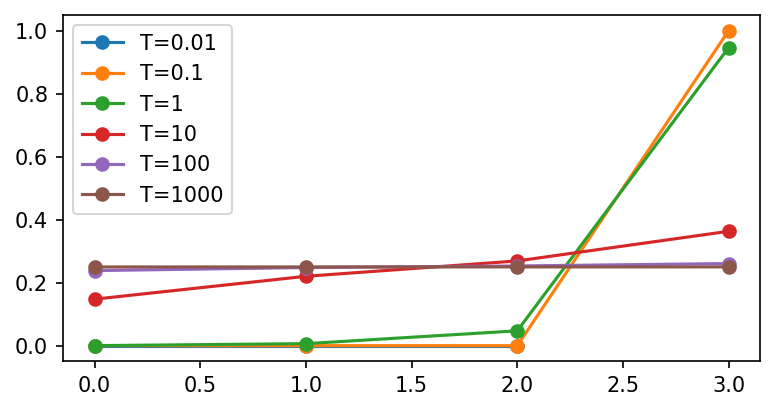

In [6]:
plt.figure(figsize=(6, 3))
logits = np.asarray([1, 5, 7, 10])
Ts = [0.01, 0.1, 1, 10, 100, 10000]
for T in Ts:
    plt.plot(softmax_with_t(logits, T), '-o')
plt.legend(['T=0.01', 'T=0.1', 'T=1', 'T=10', 'T=100', 'T=1000'])

### model.generate

- `do_sample=True`：
- 温度越高，gibberish（乱语），raw token 依然会被采样到；
- 温度越低，coherent（连贯有条理）
    - less weird 
    - temperature →0, temperature scaled sampling becomes equal to greedy decoding
- coherence（low temperature） & diversity（high temperature）：trade off

In [7]:
# https://openai.com/research/better-language-models
prompt = 'In a shocking finding, scientist discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. Even more surprising to the researchers was the fact that the unicorns spoke perfect English.'
input_ids = tokenizer(prompt, return_tensors='pt').input_ids
input_ids

tensor([[  818,   257, 14702,  4917,    11, 11444,  5071,   257, 27638,   286,
         28000, 19942,  2877,   287,   257,  6569,    11,  4271, 31286,  1850,
         19272,    11,   287,   262,   843,   274, 21124,    13,  3412,   517,
          6452,   284,   262,  4837,   373,   262,  1109,   326,   262, 28000,
         19942,  5158,  2818,  3594,    13]])

In [8]:
# top_k=0 在整个词表上进行采样
output_t = model.generate(input_ids, max_length=128, do_sample=True, temperature=0.5, top_k=0)
tokenizer.decode(output_t[0])

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


'In a shocking finding, scientist discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. Even more surprising to the researchers was the fact that the unicorns spoke perfect English.\n\nThe scientists, from the University of California, Riverside, spent a year in the region, visiting the area with a camera and recording the animals.\n\nThe team found that the unicorns are part of an ancient species of goats that lived in the region thousands of years ago.\n\nThe researchers believe the unicorns are descendants of the ancient species, which was the size of a large horse and had'

In [9]:
output_t = model.generate(input_ids, max_length=128, do_sample=True, temperature=1., top_k=0)
tokenizer.decode(output_t[0])

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


'In a shocking finding, scientist discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. Even more surprising to the researchers was the fact that the unicorns spoke perfect English.\n\nThe scientists, from the University of Copenhagen, concluded the unicorns must be distinguished from goats and other wild herbivores because they were sensitive to heat and high altitude.\n\nThey have never observed unicorns wandering in the wild so far even though the animals have been photographed in the wild by ornithologists in the U.S. and Britain.\n\n#1 The Magic Banana\n\n'

In [10]:
output_t = model.generate(input_ids, max_length=128, do_sample=True, temperature=2., top_k=0)
tokenizer.decode(output_t[0])

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


"In a shocking finding, scientist discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. Even more surprising to the researchers was the fact that the unicorns spoke perfect English.oursphaseth laboveota Badaga.... farming, EtGalalloc Rampage espresso Booted Nicola flying CanberraReady assumejar knowing Manyremeordibel sou MohammadAM house spimgurRoll nowTennormöbomb back Changesis nneticantconfailedloochalvi�il'smann syments billionsaheadLearn unknown adoreallasTo estimate la par...) quality little flowfuck resize overseeHigherStudioQuestion SEALaurKat x rock"

## top_k & nucleus sampling (top_p)

- 平衡 coherent & diversity 的另外一种方式，truncate the distribution of the vocabulary. 
    - 在 coherent 中寻求 diversity
- top-k 与 nucleus sampling (top-p)：限制采样的范围（tokens）；
    - top-k：刚性的限制
        - 避免低概率地选择
        - top_k == 0 时，deactivate top_k，不对候选 tokens 的数量进行限制
    - nucleus sampling（top-p）：核采样
- 参考：
    - https://huggingface.co/blog/how-to-generate

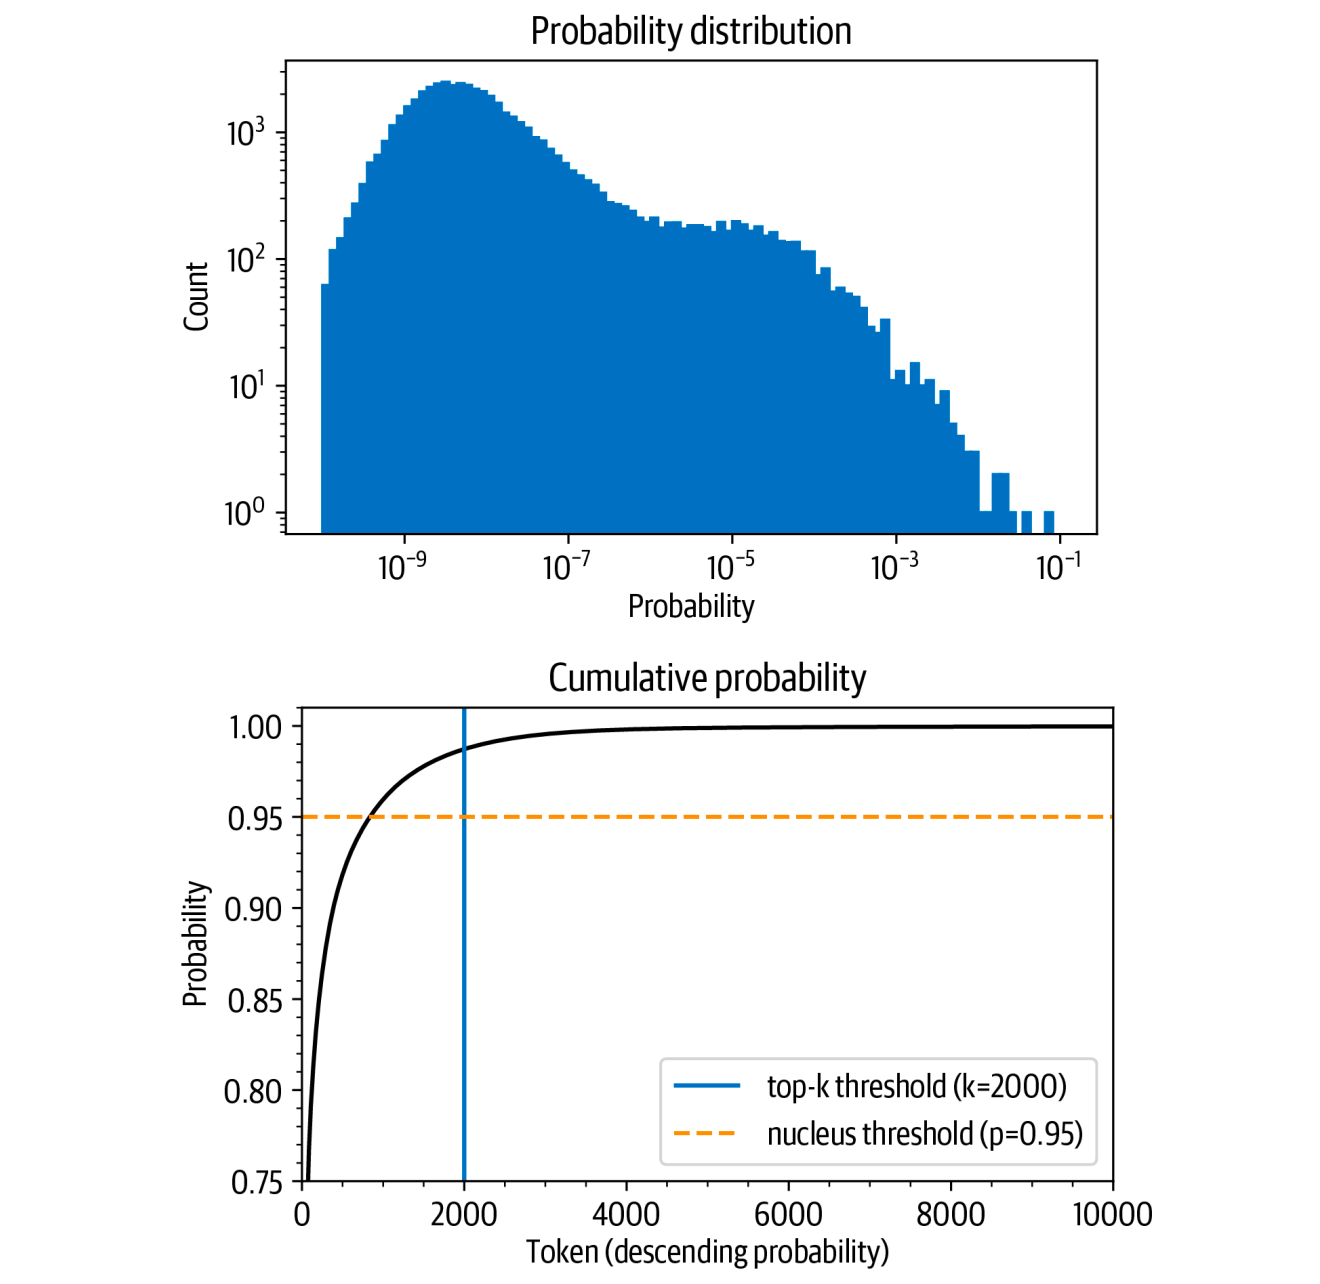

In [11]:
Image('../imgs/top_k_top_p.png', width=600)

In [12]:
output_topk = model.generate(input_ids, max_length=128, do_sample=True, top_k=50)
print(tokenizer.decode(output_topk[0]))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


In a shocking finding, scientist discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. Even more surprising to the researchers was the fact that the unicorns spoke perfect English.

Dr. Jose Crespo, an anthropologist at the University of the Andes suggested that the group of "unicorns" were in fact native South American animals, who had migrated to the Altiplano desert after their valley was destroyed by humans over a period of time.

As reported by The Herald, the unicorns lived in an isolated valley, which was found to be riddled with the


In [13]:
output_topp = model.generate(input_ids, max_length=128, do_sample=True, top_p=0.90)
print(tokenizer.decode(output_topp[0]))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


In a shocking finding, scientist discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. Even more surprising to the researchers was the fact that the unicorns spoke perfect English.

The area where the unicorn herd is found is a relatively unexplored valley of the Cordillera de Tierra, an immense mountain range in central Bolivia, about 60 km (40 miles) east of the Andes mountains. It's located in a remote part of the territory, where the government hasn't been able to develop mining operations and therefore hasn't had much access. The scientists were looking for the
